# XGBOOST

In [1]:
import pandas as pd 
data = pd.read_csv("../data/transaction_data.csv")
data = data[data["type"].isin(["TRANSFER", "CASH_OUT"])]

In [2]:
from sklearn.model_selection import train_test_split

X = data[["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig", 
          "oldbalanceDest", "newbalanceDest"]]

Y = data["isFraud"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, stratify=Y, random_state=42
)

print(f'Shape of X_train:   {X_train.shape}')
print(f'Shape of X_test:    {X_test.shape}')

Y_train_fraud = Y_train.mean()
Y_test_fraud = Y_test.mean()

print(f'y_train fraud rate: {Y_train_fraud:.3%}')
print(f'y_test_fraud rate:  {Y_test_fraud:.3%}')

Shape of X_train:   (2216327, 7)
Shape of X_test:    (554082, 7)
y_train fraud rate: 0.296%
y_test_fraud rate:  0.297%


# Creating validation set and scaling for positive weight:
Validation set will be used to tune XGboost. We avoid tuning on test set to prevent leakage

In [ ]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, Y_train, test_size=0.2, stratify=Y_train, random_state=42
)

spw = (y_tr == 0).sum() / (y_tr == 1).sum() 
print(f"scale_pos_weight: {spw:.0f}")

scale_pos_weight: 336


In [ ]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import average_precision_score

preprocess = ColumnTransformer(
    [("cat", OneHotEncoder(), ["type"])],
    remainder="passthrough",
)

xgb = Pipeline([
    ("preprocess", preprocess),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.1,
        scale_pos_weight=spw, 
        tree_method="hist",
        n_jobs=-1,
        random_state=42,
    )),
])

xgb.fit(X_tr, y_tr) # Training with training data
proba_val = xgb.predict_proba(X_val)[:, 1] # Predictions with validation data?
print(f"Validation PR AUC: {average_precision_score(y_val, proba_val):.3f}")

Validation PR AUC: 0.962


## Finding optimal value ofr n_estimators to prevent overfitting

In [5]:
pre = ColumnTransformer([("cat", OneHotEncoder(), ["type"])], remainder="passthrough")
X_tr_enc = pre.fit_transform(X_tr)
X_val_enc = pre.transform(X_val)

xgb_es = XGBClassifier(
    n_estimators=2000,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=spw,
    eval_metric="aucpr",
    early_stopping_rounds=50,
    tree_method="hist",
    n_jobs=-1,
    random_state=42,
)

xgb_es.fit(X_tr_enc, y_tr, eval_set=[(X_val_enc, y_val)], verbose=100)

print(f"Best number of trees: {xgb_es.best_iteration + 1}")
print(f"Best validation PR AUC: {xgb_es.best_score:.3f}")

[0]	validation_0-aucpr:0.67554
[100]	validation_0-aucpr:0.95134
[200]	validation_0-aucpr:0.96018
[300]	validation_0-aucpr:0.96193
[338]	validation_0-aucpr:0.96199
Best number of trees: 289
Best validation PR AUC: 0.962


earlier guess of 300 trees was already about right, so the score stays at 0.962. Early stopping didn’t improve the score, but it confirmed the right number of trees from data instead of guesswork, and it guards against overfitting when you change settings in step 4.


## Small settings search of optimal values for max_depth and Learning_rate:

In [6]:
results = []

for depth in [4, 6, 8]:
    for lr in [0.05, 0.1]:
        model = XGBClassifier(
            n_estimators=2000,
            max_depth=depth,
            learning_rate=lr,
            scale_pos_weight=spw,
            eval_metric="aucpr",
            early_stopping_rounds=50,
            tree_method="hist",
            n_jobs=-1,
            random_state=42,
        )
        model.fit(X_tr_enc, y_tr, eval_set=[(X_val_enc, y_val)], verbose=False)
        results.append({
            "max_depth": depth,
            "learning_rate": lr,
            "best_trees": model.best_iteration + 1,
            "val_pr_auc": model.best_score,
        })

results_df = pd.DataFrame(results).sort_values("val_pr_auc", ascending=False)
print(results_df)

   max_depth  learning_rate  best_trees  val_pr_auc
1          4           0.10         662    0.963613
0          4           0.05        1358    0.963438
5          8           0.10         175    0.962285
3          6           0.10         289    0.962160
2          6           0.05         610    0.962041
4          8           0.05         398    0.961924


## Final model vs logisitc regression on test set

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Final model with the chosen settings
final_xgb = XGBClassifier(
    n_estimators=662,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=spw,
    tree_method="hist",
    n_jobs=-1,
    random_state=42,
)
final_xgb.fit(X_tr_enc, y_tr)

# Choose the threshold by cost on validation
proba_val = final_xgb.predict_proba(X_val_enc)[:, 1]
grid = np.linspace(0.01, 0.99, 99)
costs = []
for t in grid:
    pred = (proba_val >= t).astype(int)
    fn = ((pred == 0) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    costs.append(fn * 500 + fp * 10)
best_t_xgb = grid[np.argmin(costs)]
print(f"XGBoost threshold: {best_t_xgb:.2f}")

# Score the test set once
X_test_enc = pre.transform(X_test)
proba_test = final_xgb.predict_proba(X_test_enc)[:, 1]
y_pred_xgb = (proba_test >= best_t_xgb).astype(int)

cm = confusion_matrix(Y_test, y_pred_xgb)
fn, fp = cm[1, 0], cm[0, 1]
print(cm)
print(f"PR AUC:    {average_precision_score(Y_test, proba_test):.3f}")
print(f"Recall:    {recall_score(Y_test, y_pred_xgb):.3f}")
print(f"Precision: {precision_score(Y_test, y_pred_xgb):.3f}")
print(f"F1:        {f1_score(Y_test, y_pred_xgb):.3f}")
print(f"Cost:      £{fn * 500 + fp * 10:,}")

XGBoost threshold: 0.52
[[550684   1755]
 [    20   1623]]
PR AUC:    0.963
Recall:    0.988
Precision: 0.480
F1:        0.646
Cost:      £27,550


## M3: XGBoost summmary and takeaways


### Why XGBoost
Logistic regression scores a transaction by adding up weighted features, so it can only separate fraud from genuine transactions with a straight-line boundary. Fraud patterns tend to depend on combinations of conditions, such as a transfer that also empties the account, which a single weighted sum struggles to capture. Gradient-boosted trees can learn these combinations directly, so XGBoost was the natural next step after the logistic regression baseline.

### Setup
To tune the model without touching the test set, I split the training data again, keeping 80% for fitting (`X_tr`, `y_tr`) and 20% as a validation set (`X_val`, `y_val`), stratified so both keep the same fraud rate. The test set stayed untouched until the final comparison. Only the `type` column needed encoding, so I one-hot encoded it and passed the other columns through unchanged. Trees don't need scaling, because each split only depends on the order of the values. Fraud makes up about 1 in 337 training rows, so I set `scale_pos_weight` to the genuine-to-fraud ratio of 336. A first model with 300 trees of depth 6 reached a validation PR AUC of 0.962, compared with about 0.59 for logistic regression.

### Early stopping
Rather than guess the number of trees, I let the validation set decide. Early stopping needs XGBoost to score the validation set after every tree, and that data is passed straight to XGBoost rather than through the Pipeline's encoding step, so I encoded the training and validation sets myself before fitting. I allowed up to 2,000 trees and told XGBoost to stop once validation PR AUC hadn't improved for 50 trees in a row. The best score came at 289 trees with a PR AUC of 0.962. The score rose quickly over the first 200 trees and then flattened, so the original guess of 300 was already close.

### Settings search
I tried tree depths of 4, 6 and 8 with learning rates of 0.05 and 0.1, using early stopping for each run. All six scored between 0.962 and 0.964 on validation, a spread small enough to be noise, so the model isn't sensitive to these settings. Shallow trees with many rounds matched deep trees with few. I chose a depth of 4 and a learning rate of 0.1, which needed 662 trees. It had the top score and the simplest trees, which makes it less likely to overfit and easier to explain.

### Test-set comparison
I trained the final model on the training portion and chose its threshold on the validation set, using the same cost calculation as in M2 (£500 per missed fraud, £10 per wrongly blocked customer). The cheapest threshold was 0.52. I then scored the test set once. XGBoost reached a PR AUC of 0.963 against 0.588 for logistic regression. It missed 20 frauds instead of 397 and wrongly blocked 1,755 genuine customers instead of 8,121, giving a recall of 0.988 and a precision of 0.480. The expected cost fell from £279,710 to £27,550, a 90% reduction. Unlike moving the threshold, which only trades one kind of mistake for the other, the better model reduced both at once. The test PR AUC matched the validation score, which suggests the model generalises well to unseen data.

### Takeaways
**Boosting vs bagging.** Boosting, which XGBoost uses, builds trees one after another. Each new tree learns to correct the mistakes the earlier trees still make, and the final prediction is the sum of all their corrections, which mainly reduces bias. Bagging, used in Random Forest, builds trees independently, each on a random sample of the rows, and averages their predictions, which mainly reduces variance.

**Why trees don't need scaling.** A tree splits data by asking whether a value is above or below a cut-off. That only depends on the order of the values. Scaling changes the numbers but keeps their order, so the same rows end up on each side of every split.

**What `scale_pos_weight` does.** With about 336 genuine transactions for every fraud, a model can score well during training by mostly ignoring fraud. Setting `scale_pos_weight` to 336 multiplies the training error on each fraud row by 336, so the fraud rows carry the same total weight as the genuine rows and the model has to learn to detect fraud. The value comes from the class ratio, not from a judgement about how costly a missed fraud is. That judgement is handled separately by the £500 and £10 costs when choosing the threshold after training.

### Limitations
The settings and the threshold were both chosen on the same validation set, so they may be slightly tuned to it, although the untouched test result matching the validation score eases that concern. The scores are very high, which may partly reflect quirks in how PaySim simulates account balances, such as accounts being emptied exactly and destination balances that don't add up. Real bank data would likely be harder. I'll check this with SHAP in M4. Finally, the £500 and £10 costs are illustrative, and real costs would lead to a different threshold.

---

# Explainability

Goal here it to identify features that the model depends on, so the model itself can be explained to potential users like banks. It will also reveal if the observed PR AUC is a result of quirks in the datasets amounts or actual learning the model has acheived from the datasets features. 


In [15]:
from sklearn.inspection import permutation_importance

feature_names = pre.get_feature_names_out()

perm = permutation_importance(
    final_xgb, X_val_enc, y_val.to_numpy(),
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "mean_drop": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("mean_drop", ascending=False)

print(importance_df)

                     feature  mean_drop       std
4   remainder__oldbalanceOrg   0.958907  0.000109
5  remainder__newbalanceOrig   0.897294  0.000742
3          remainder__amount   0.564433  0.010136
6  remainder__oldbalanceDest   0.303612  0.008246
7  remainder__newbalanceDest   0.233519  0.006017
0         cat__type_CASH_OUT   0.174078  0.008725
2            remainder__step   0.053477  0.001978
1         cat__type_TRANSFER   0.000000  0.000000


The model almost entirely depends on senders balance before and after a transaciton. Such features allow fraudulent actions like emptying of accounts to be spotted. OldbalanceOrg caused PRAUC to fall to about 0.04, whilst new_balance_org caused it to fall to about 0.10. Empyting accounts is a genuine fraud sign and banks do know balances at the time of a transactions so this information is not leakage. 

Single observed drop never adds up to 0.963 because this value was achieved by features working together. Scrambling a single feature causes patterns that depended on tha feature to fully be established, so each drop also suffers from the absence of these combintions. 

# Calculating SHAP

In [16]:
import sys
!{sys.executable} -m pip install shap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 12.0 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 62.9 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.2.6 which is incompatible.
soccerdata 1.8.7 requires packaging<25.0,>=24.1, but you have packaging 23.2 which is incompatible.
streamlit 1.32.0 requires numpy<2,>=1.19.3, but you have numpy 2.2.6 which is incompatible.
numba 0.59.1 requires numpy<1.27,>=1.22, but you have numpy 2.2.6 which is incompatible.
pywavelets 1.5.0 requires numpy<2.0,>=1.22.4,

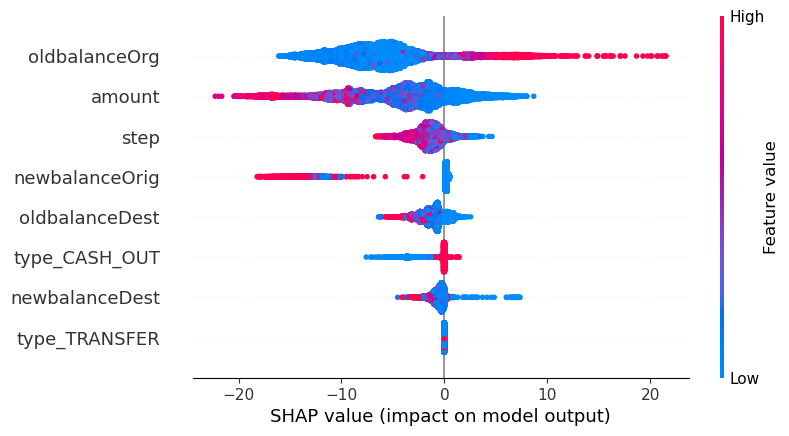

In [17]:
import shap

clean_names = [n.split("__")[1] for n in feature_names]

rng = np.random.default_rng(42)
idx = rng.choice(len(X_val_enc), size=20000, replace=False)
X_sample = X_val_enc[idx]

explainer = shap.TreeExplainer(final_xgb)
shap_values = explainer(X_sample)
shap_values.feature_names = clean_names

shap.plots.beeswarm(shap_values, max_display=10)

In [18]:
row = 0
print("base + SHAP values:", shap_values.base_values[row] + shap_values.values[row].sum())
print("model raw output:  ", final_xgb.predict(X_sample[[row]], output_margin=True)[0])

base + SHAP values: -14.999698
model raw output:   -14.999696


In [19]:
check = pd.DataFrame({
    "emptied": np.isclose(X_val["amount"], X_val["oldbalanceOrg"]) & (X_val["oldbalanceOrg"] > 0),
    "zero_start_balance": X_val["oldbalanceOrg"] == 0,
    "isFraud": y_val,
})
print(check.groupby("isFraud").mean())

          emptied  zero_start_balance
isFraud                              
0        0.000002            0.473656
1        0.977930            0.003805


- Impurity importance counts how much each feature was used to split trees during training. Features with many distinct values, like amount, offer more possible split points, so they get used and credited more, even when the splits add little. Because it’s measured on training data, it can also reward splits that only fit noise.

- A SHAP value is one feature’s push on one transaction’s score. For every transaction, the base value (the model’s average score) plus that transaction’s SHAP values adds up exactly to the model’s raw output (log-odds) for it.

- Importance isn’t causation, because it measures what the model relies on to predict, which comes from correlations in the training data. A feature can be important because it’s linked to fraud, or acts as a proxy for something else, without causing it. Here, sender balances dominate because PaySim’s fraud almost always empties a funded account, which is a property of the simulator rather than a cause of fraud.


### Why explainability
XGBoost reached a test PR AUC of 0.963, far above logistic regression. Before trusting that number, I needed to know which features the model relies on and whether it was learning genuine fraud behaviour or something specific to the PaySim simulator. A bank would also need to explain a model's decisions to customers and regulators, so understanding what drives the predictions matters as much as the score.

### Permutation importance
I measured how much validation PR AUC fell when each feature was randomly shuffled, which breaks its link to fraud while leaving everything else unchanged. I repeated each shuffle five times and averaged the drops. Shuffling the sender's starting balance (`oldbalanceOrg`) dropped PR AUC by 0.959, leaving the model at roughly random performance, and shuffling the sender's balance afterwards (`newbalanceOrig`) dropped it by 0.897. `amount` was the next most important at 0.56, followed by the destination balances, transaction type and `step`. The `type_TRANSFER` column showed no importance, because after filtering it is always the opposite of `type_CASH_OUT`, so the model only needed one of them. The drops don't add up to the full score, because features work together and shuffling one also breaks the patterns it forms with others.

### SHAP
SHAP shows how much each feature pushed each individual transaction's score towards fraud or towards genuine. For every transaction, the model's average score plus the SHAP values of its features adds up exactly to the model's raw output, which I confirmed on a sample transaction. The summary plot of 20,000 validation transactions showed that a high starting balance pushes strongly towards fraud, while money remaining in the account afterwards pushes strongly towards genuine. Large amounts often pushed towards genuine, which looks backwards (considering earlier findings that fraudulent transactions are usually larger) until you consider that the model judges the amount relative to the balance rather than on its own.In this dataset, large amounts are often associated with money being left. Overall, the model is mainly asking whether a funded account has been emptied.

### Checking the pattern directly
To test this, I counted how often each class empties a funded account (amount equal to the starting balance, with a starting balance above zero). 97.8% of fraud transactions did, compared with 0.0002% of genuine ones. 47% of genuine transactions started from a zero balance while still sending money, which isn't possible for a real account and points to a simulator quirk. This one pattern separates fraud from genuine transactions almost perfectly, which explains most of XGBoost's very high score.


### Limitations
The model's strength comes mostly from a pattern the simulator builds into nearly every fraud. In real banking data, genuine customers sometimes empty their accounts, fraudsters don't always take everything, and zero-balance payments wouldn't appear, so I would expect noticeably lower performance on real transactions. A model for real use would need features that capture behaviour over time, such as how unusual a payment is for that customer or how many accounts a destination receives money from, rather than relying on a single balance pattern.